In [19]:
import pandas as pd
import matplotlib as plt
import glob as g


In [20]:
# roulette_20_percent_csv_files = list(g.glob("training_logs/20 Percent Test/Roulette/Logs/*.csv"))
# roulette_10_percent_csv_files = list(g.glob("training_logs/10 Percent Test/Roulette/Logs/*.csv"))

# roulette_20_percent_logs = {
#     file.split("-")[1].replace("_","."): pd.read_csv(file)
#     for file in roulette_20_percent_csv_files
# }

# roulette_10_percent_logs = {
#     file.split("-")[1].replace("_", "."): pd.read_csv(file)
#     for file in roulette_10_percent_csv_files
# }


roulette_10_percent_csv_files = list(g.glob("logs/roulette_10_percent_test/*.csv"))
roulette_20_percent_csv_files = list(g.glob("logs/roulette_20_percent_test/*.csv"))

roulette_10_percent_logs = {
    file.split("-")[1].replace("_", "."): pd.read_csv(file)
    for file in roulette_10_percent_csv_files
}

roulette_20_percent_logs = {
    file.split("-")[1].replace("_", "."): pd.read_csv(file)
    for file in roulette_20_percent_csv_files
}

tournament_20_percent_csv_files = list(g.glob("logs/tournament_20_percent_test/*.csv"))
tournament_10_percent_csv_files = list(g.glob("logs/tournament_10_percent_test/*.csv"))

# for file in tournament_20_percent_csv_files:
#     print(file)

tournament_20_percent_logs = {
    file.split("-")[1].replace("_","."): pd.read_csv(file)
    for file in tournament_20_percent_csv_files
}

tournament_10_percent_logs = {
    file.split("-")[1].replace("_", "."): pd.read_csv(file)
    for file in tournament_10_percent_csv_files
}


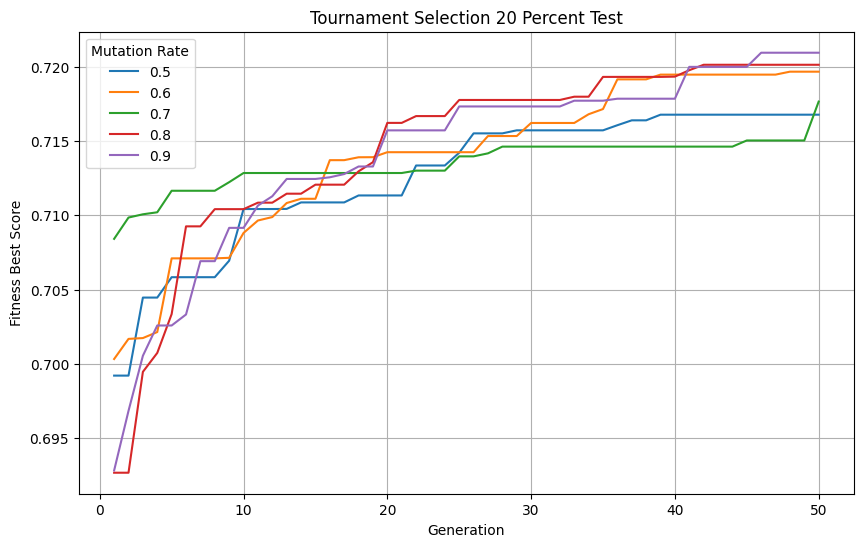

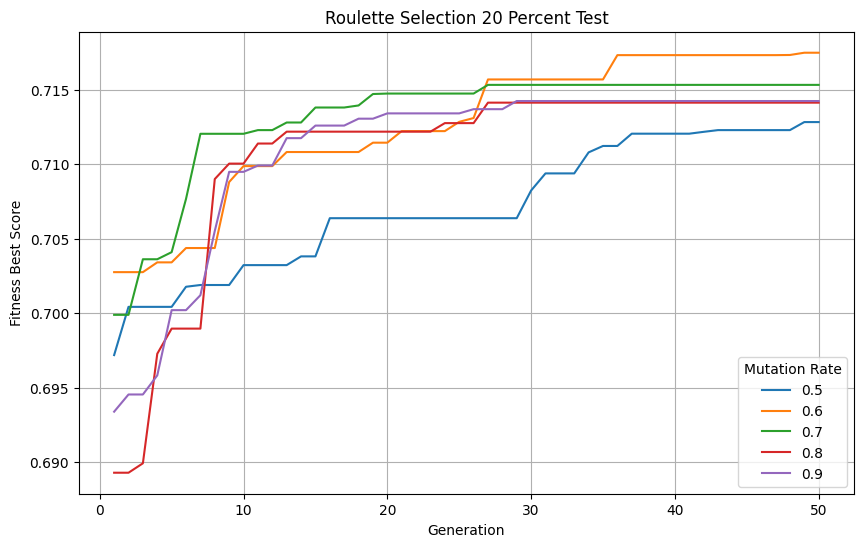

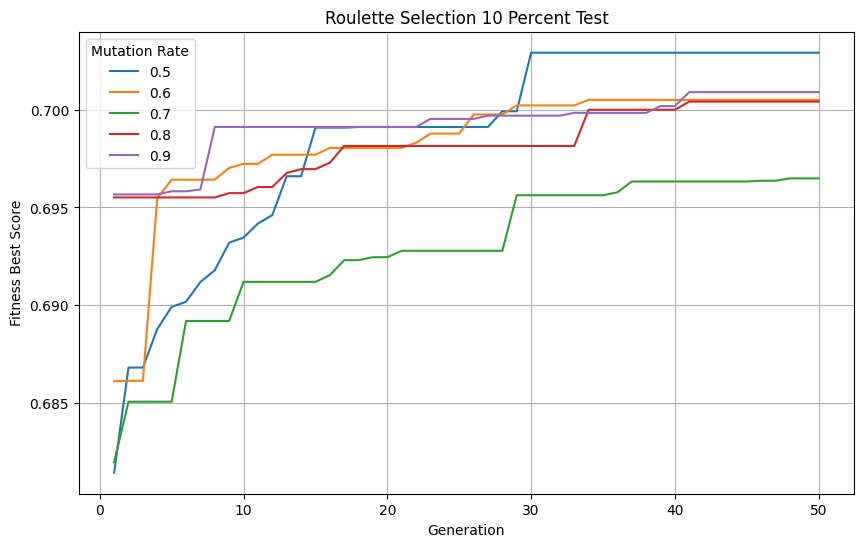

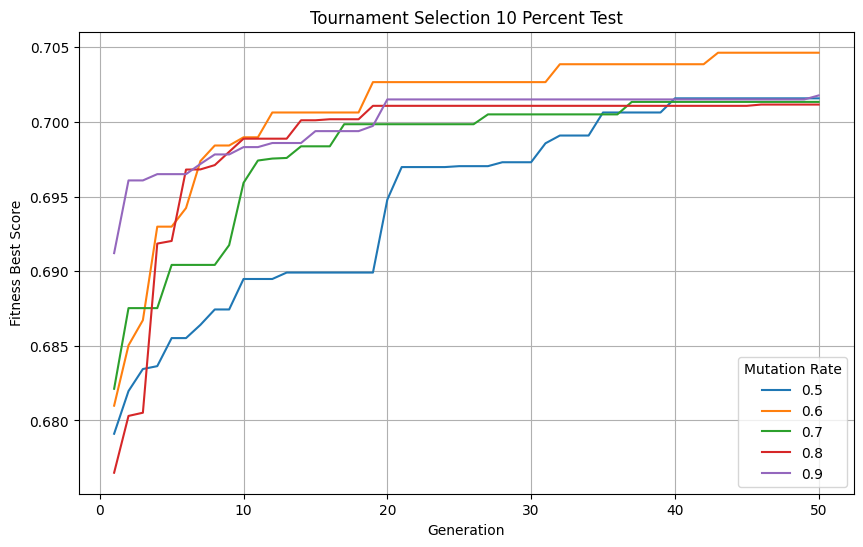

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
for name, df in sorted(tournament_20_percent_logs.items()):
    plt.plot(
        df["generation"],
        df["global_best_score"],
        label=name
    )
    
plt.xlabel("Generation")
plt.ylabel("Fitness Best Score")
plt.title("Tournament Selection 20 Percent Test")
plt.legend(title = "Mutation Rate")
plt.grid()

plt.show()

plt.figure(figsize=(10,6))
for name, df in sorted(roulette_20_percent_logs.items()):
    plt.plot(
        df["generation"],
        df["global_best_score"],
        label=name
    )
    
plt.xlabel("Generation")
plt.ylabel("Fitness Best Score")
plt.title("Roulette Selection 20 Percent Test")
plt.legend(title = "Mutation Rate")
plt.grid()

plt.show()

plt.figure(figsize=(10,6))
for name, df in sorted(roulette_10_percent_logs.items()):
    plt.plot(
        df["generation"],
        df["global_best_score"],
        label=name
    )
    
plt.xlabel("Generation")
plt.ylabel("Fitness Best Score")
plt.title("Roulette Selection 10 Percent Test")
plt.legend(title = "Mutation Rate")
plt.grid()

plt.show()

plt.figure(figsize=(10,6))
for name, df in sorted(tournament_10_percent_logs.items()):
    plt.plot(
        df["generation"],
        df["global_best_score"],
        label=name
    )
    
plt.xlabel("Generation")
plt.ylabel("Fitness Best Score")
plt.title("Tournament Selection 10 Percent Test")
plt.legend(title = "Mutation Rate")
plt.grid()

plt.show()



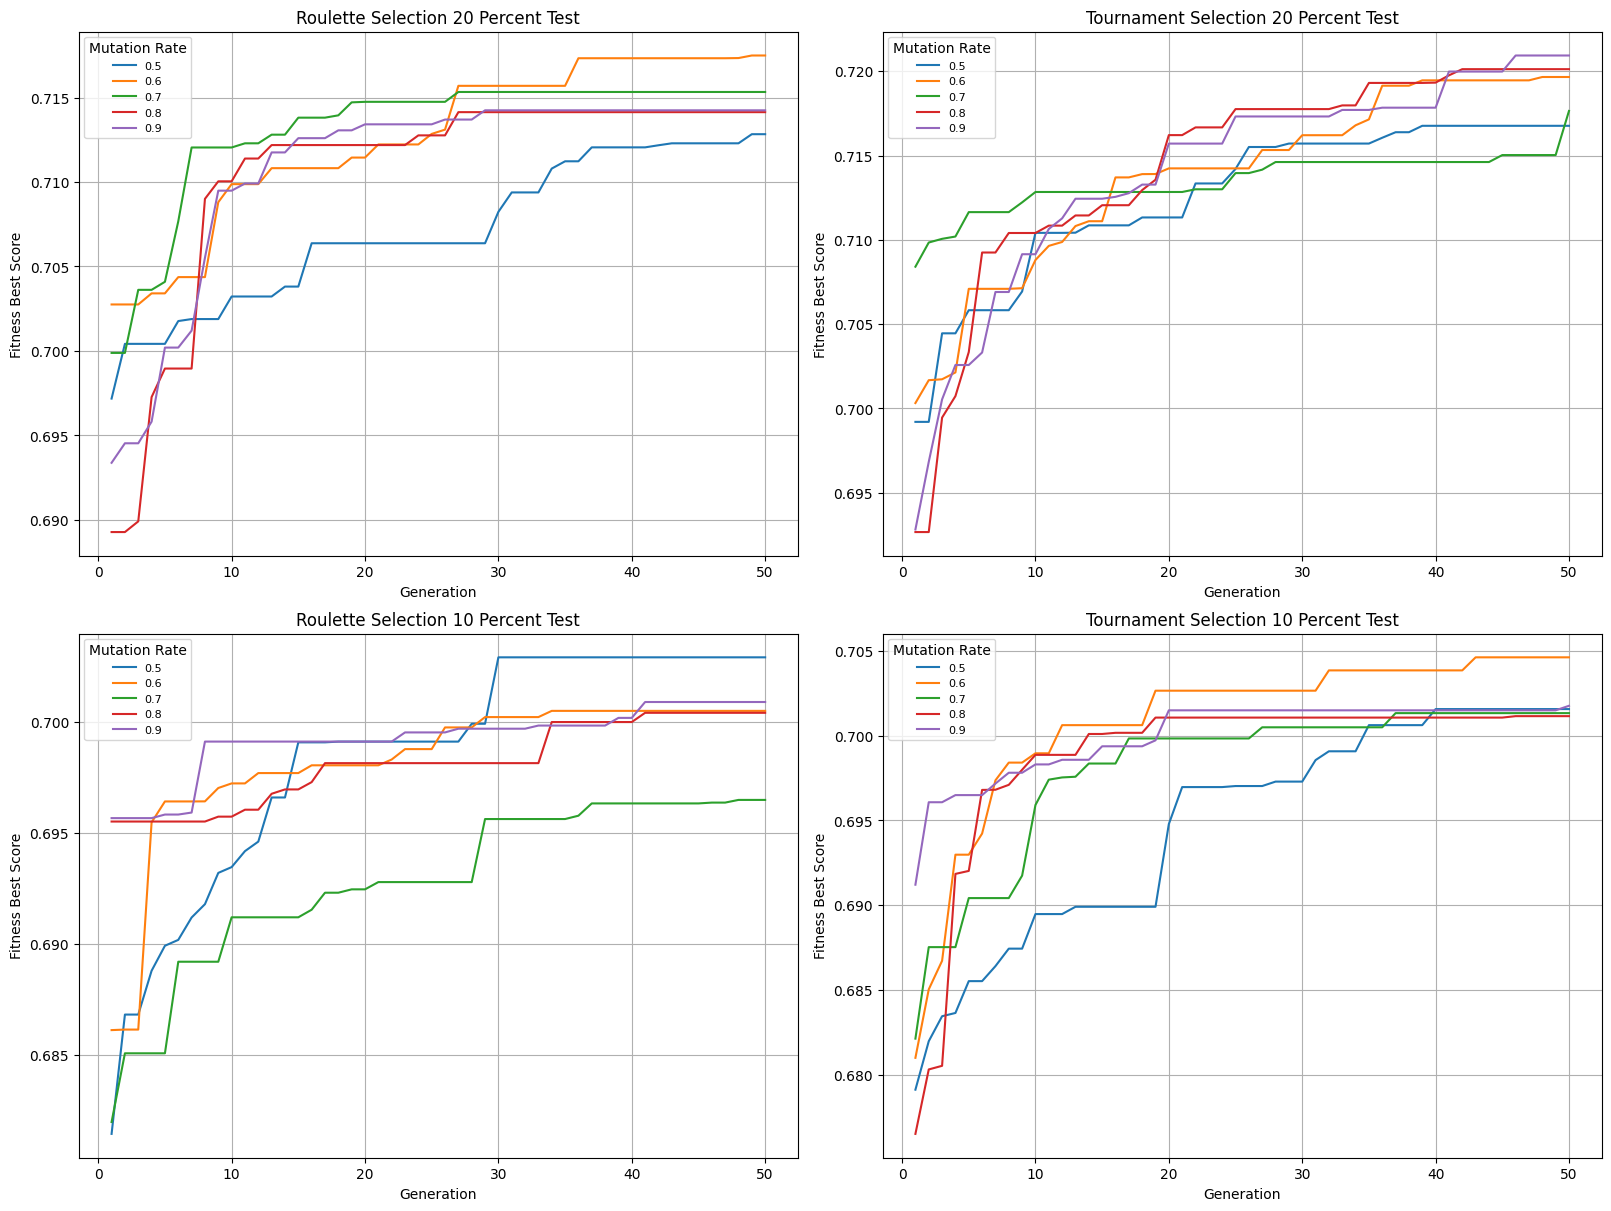

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 12), constrained_layout=True)

plots = [
    ("Roulette Selection 20 Percent Test", roulette_20_percent_logs),
    ("Tournament Selection 20 Percent Test", tournament_20_percent_logs),
    ("Roulette Selection 10 Percent Test", roulette_10_percent_logs),
    ("Tournament Selection 10 Percent Test", tournament_10_percent_logs),
]

for ax, (title, logs) in zip(axes.flat, plots):
    for name, df in sorted(logs.items()):
        ax.plot(
            df["generation"],
            df["global_best_score"],
            label=name
        )

    ax.set_xlabel("Generation")
    ax.set_ylabel("Fitness Best Score")
    ax.set_title(title)
    ax.grid(True)
    ax.legend(title="Mutation Rate", fontsize=8)

plt.show()

In [23]:
tournament_10_percent_logs['0.5'].iloc[:, 3].idxmax()

39

In [24]:
roulette_20_percent_logs['0.6'].iloc[:, 3].argmax()

np.int64(48)

In [25]:
roulette_20_percent_logs['0.6'].loc[43, 'global_best']

'[0 0 0 1 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0\n 0 0 1 1 1 0 1 1 1 1 0 0 1 0 1000 8 5 1 1]'

In [ ]:
from numpy import full


all_logs = {}

full_logs = {
    "Roulette_20": roulette_20_percent_logs,
    "Roulette_10": roulette_10_percent_logs,
    "Tournament_20": tournament_20_percent_logs,
    "Tournament_10": tournament_10_percent_logs,
}

for method, logs in full_logs.items():
    for mutation_rate, df in logs.items():
        best_idx = df['global_best_score'].idxmax()
        best_df = df.loc[[best_idx]]
        all_logs[f"{method}_{mutation_rate}"] = best_df

In [27]:
new_df = pd.DataFrame()
for name, df in all_logs.items():
    for i in range(len(df)):
        row = df.iloc[[i]].copy()
        row['method'] = name
        row['execution_time'] = (row['execution_finish'] - row['overall_start'])
        
        new_df = pd.concat([new_df, row], ignore_index=True)



In [28]:
# pd.set_option('display.max_rows', None)
# pd.set_option('display.width', None)
new_df[['global_best_score', 'method', 'execution_time','generation']]

,global_best_score,method,execution_time,generation
0,0.712830,Roulette_20_0.5,2979.557634,49
1,0.717487,Roulette_20_0.6,4089.515669,49
2,0.715328,Roulette_20_0.7,2263.229139,27
3,0.714134,Roulette_20_0.8,3527.637802,27
4,0.714243,Roulette_20_0.9,3279.015251,29
5,0.702906,Roulette_10_0.5,2993.104974,30
6,0.700494,Roulette_10_0.6,3385.476198,34
7,0.696483,Roulette_10_0.7,1839.729268,48
8,0.700407,Roulette_10_0.8,1624.946169,41
9,0.700893,Roulette_10_0.9,1649.995526,41


In [29]:
new_df.loc[1]['global_best']


'[0 0 1 1 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0\n 1 1 0 1 1 0 1 1 1 0 0 0 1 0 1000 8 5 1 1]'

In [30]:
best_score = 0
best_name = None
best_feature = None


for name, df in all_logs.items():
    idx = df['global_best_score'].idxmax()
    
    if (df.loc[idx, 'global_best_score'] > best_score):
        best_score = df.loc[idx, 'global_best_score']
        best_name = name
        best_feature = df.loc[idx, 'global_best']
        
print(best_name, best_score, best_feature)

Roulette_20_0.6 0.717486776961002 [0 0 1 1 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 0
 1 1 0 1 1 0 1 1 1 0 0 0 1 0 1000 8 5 1 1]


In [31]:
for name, df in tournament_10_percent_logs.items():
    print(name, df['global_best_score'].max())


0.5 0.701574794335939
0.6 0.704629859367017
0.7 0.7013363481015882
0.8 0.701158051285317
0.9 0.7017693685312512
